In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns
from matplotlib import font_manager as fm
from IPython.display import display


# ===== 한글 글꼴: Windows(맑은 고딕) / macOS(AppleGothic) / Linux(나눔) 자동 선택 =====
def set_korean_font():
    available = {f.name for f in fm.fontManager.ttflist}
    for name in ('Malgun Gothic', 'AppleGothic', 'Apple SD Gothic Neo', 'NanumGothic', 'Noto Sans CJK KR'):
        if name in available:
            plt.rcParams['font.family'] = name
            plt.rcParams['font.sans-serif'] = [name]
            break
    else:
        print('한글 글꼴을 찾지 못했습니다. 그래프의 한글이 깨질 수 있습니다.')
        name = None
    plt.rcParams['axes.unicode_minus'] = False
    return name

print('사용 폰트:', set_korean_font())


# ===== 프로젝트 경로 설정 =====
# PyCharm에서 어느 폴더 기준으로 실행하든 pyproject.toml이 있는 프로젝트 루트를 찾음
def find_project_root(start=None):
    here = Path(start or Path.cwd()).resolve()
    for d in (here, *here.parents):
        if (d / 'pyproject.toml').exists() and (d / '1.Rawdata_EDA').exists():
            return d
    raise FileNotFoundError('Port_Cast_Final 프로젝트 루트(pyproject.toml)를 찾을 수 없습니다.')

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / '1.Rawdata_EDA' / 'Data'                 # 원본: weather_raw2.csv
OUTPUT_DIR = PROJECT_ROOT / '1.Rawdata_EDA' / 'Output' / '기상특보_전처리'  # 이 노트북이 만드는 CSV
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('원본 폴더:', DATA_DIR)
print('산출물 폴더:', OUTPUT_DIR)


def load_dataset(filename, cols=None, sheet_name=0):
    filename = Path(filename)

    # 확장자가 없으면 CSV 파일로 처리
    if not filename.suffix:
        filename = filename.with_suffix('.csv')

    # 파일 이름만 주면 1.Rawdata_EDA/Data 폴더에서 찾음
    target_path = DATA_DIR / filename.name if filename.parent == Path('.') else filename

    print('읽는 파일:', target_path.resolve())

    if not target_path.exists():
        raise FileNotFoundError(f'파일을 찾을 수 없습니다: {target_path.resolve()}')

    # 확장자에 따라 파일 읽기
    ext = target_path.suffix.lower()

    if ext == '.csv':
        return pd.read_csv(target_path, usecols=cols, encoding='utf-8-sig')

    elif ext in ['.xlsx', '.xls']:
        return pd.read_excel(target_path, sheet_name=sheet_name, usecols=cols)

    else:
        raise ValueError(f'지원하지 않는 파일 형식입니다: {ext}')


사용 폰트: Malgun Gothic
원본 폴더: C:\work\Port_Cast_Final\1.Rawdata_EDA\Data
산출물 폴더: C:\work\Port_Cast_Final\1.Rawdata_EDA\Output\기상특보_전처리


In [2]:
df = load_dataset('weather_raw2.csv')

읽는 파일: C:\work\Port_Cast_Final\1.Rawdata_EDA\Data\weather_raw2.csv


In [3]:
df.head()

,TM_FC,TM_EF,TM_IN,STN,REG_ID,WRN,LVL,CMD,GRD,CNT,RPT
0,2020-01-06 16:00:00,2020-01-07 23:58:00,2020-01-06 15:14:00,159,S1311100,V,1,1,0,4,101
1,2020-01-07 16:00:00,2020-01-07 18:00:00,2020-01-07 15:34:00,159,S1311100,V,2,1,0,4,101
2,2020-01-09 04:00:00,2020-01-09 06:00:00,2020-01-09 03:35:00,159,S1311100,V,2,3,0,4,101
3,2020-01-18 02:00:00,2020-01-18 03:00:00,2020-01-18 01:45:00,159,S1311100,V,2,1,0,4,101
4,2020-01-18 10:00:00,2020-01-18 11:00:00,2020-01-18 09:58:00,159,S1311100,V,2,3,0,4,101


In [4]:
# 컬럼명 변경
df = df.rename(columns={
    'TM_FC': '발표시각',
    'TM_EF': '발효시각',
    'TM_IN': '입력시각',
    'STN': '발표관서',
    'REG_ID': '예보구역코드',
    'WRN': '특보종류',
    'LVL': '특보수준',
    'CMD': '조치'
})

In [5]:
# 불필요한 컬럼 삭제
df = df.drop(columns=['GRD', 'CNT', 'RPT'], errors='ignore')

In [6]:
# 특보종류 한글 변환
warning_map = {
    'W': '강풍',
    'R': '호우',
    'C': '한파',
    'D': '건조',
    'O': '폭풍해일',
    'N': '지진해일',
    'V': '풍랑',
    'T': '태풍',
    'S': '대설',
    'Y': '황사',
    'H': '폭염',
    'F': '안개',
    'K': '열대야'
}

df['특보종류'] = df['특보종류'].replace(warning_map)

In [7]:
# 컬럼 확인
print(df.columns.tolist())

# 특보종류별 데이터 개수
print(df['특보종류'].value_counts())

# 데이터 미리보기
display(df.head())

['발표시각', '발효시각', '입력시각', '발표관서', '예보구역코드', '특보종류', '특보수준', '조치']
특보종류
풍랑    513
태풍     32
Name: count, dtype: int64


,발표시각,발효시각,입력시각,발표관서,예보구역코드,특보종류,특보수준,조치
0,2020-01-06 16:00:00,2020-01-07 23:58:00,2020-01-06 15:14:00,159,S1311100,풍랑,1,1
1,2020-01-07 16:00:00,2020-01-07 18:00:00,2020-01-07 15:34:00,159,S1311100,풍랑,2,1
2,2020-01-09 04:00:00,2020-01-09 06:00:00,2020-01-09 03:35:00,159,S1311100,풍랑,2,3
3,2020-01-18 02:00:00,2020-01-18 03:00:00,2020-01-18 01:45:00,159,S1311100,풍랑,2,1
4,2020-01-18 10:00:00,2020-01-18 11:00:00,2020-01-18 09:58:00,159,S1311100,풍랑,2,3


In [8]:
# 전처리 데이터 CSV 저장
output_path = OUTPUT_DIR / '기상특보이력_전처리.csv'

df.to_csv(output_path, index=False, encoding='utf-8-sig')

print(f'저장 완료: {output_path.resolve()}')

저장 완료: C:\work\Port_Cast_Final\1.Rawdata_EDA\Output\기상특보_전처리\기상특보이력_전처리.csv


In [9]:
cmd_map = {
    1: '발표',
    2: '대치',
    3: '해제',
    4: '대치해제(자동)',
    5: '연장',
    6: '변경',
    7: '변경해제'
}

df['조치'] = df['조치'].replace(cmd_map)

In [10]:
df['조치'] = df['조치'].astype('string').str.strip()

cmd_map = {str(k): v for k, v in cmd_map.items()}

df['조치'] = df['조치'].replace(cmd_map)

In [11]:
df['조치'].value_counts(dropna=False)

조치
발표      319
해제      170
변경       36
변경해제     13
연장        7
Name: count, dtype: Int64

In [12]:
df.to_csv(
    OUTPUT_DIR / '기상특보이력_전처리V2.csv',
    index=False,
    encoding='utf-8-sig'
)

간단한 EDA

In [13]:
# 데이터 상태확인
print(df.shape)
print(df.info())

# 결측치 확인
print(df.isna().sum())

# 완전히 동일한 행 확인
print('중복 행:', df.duplicated().sum())

# 조치별 기록 수
print(df['조치'].value_counts(dropna=False))

(545, 8)
<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   발표시각    545 non-null    str   
 1   발효시각    545 non-null    str   
 2   입력시각    545 non-null    str   
 3   발표관서    545 non-null    int64 
 4   예보구역코드  545 non-null    str   
 5   특보종류    545 non-null    str   
 6   특보수준    545 non-null    int64 
 7   조치      545 non-null    string
dtypes: int64(2), str(5), string(1)
memory usage: 34.2 KB
None
발표시각      0
발효시각      0
입력시각      0
발표관서      0
예보구역코드    0
특보종류      0
특보수준      0
조치        0
dtype: int64
중복 행: 0
조치
발표      319
해제      170
변경       36
변경해제     13
연장        7
Name: count, dtype: Int64


In [14]:
#2. 발효시각을 datetime으로 변경
# 원본 보존
df['발효시각_원본'] = df['발효시각'].copy()

# 문자열로 변환
date_str = df['발효시각'].astype('string').str.strip()
date_str = date_str.str.replace(r'\.0$', '', regex=True)

# 12자리: YYYYMMDDHHMM
# 14자리: YYYYMMDDHHMMSS
df['발효시각'] = pd.to_datetime(date_str, errors='coerce')

mask12 = date_str.str.fullmatch(r'\d{12}').fillna(False)
mask14 = date_str.str.fullmatch(r'\d{14}').fillna(False)

df.loc[mask12, '발효시각'] = pd.to_datetime(
    date_str[mask12], format='%Y%m%d%H%M', errors='coerce'
)

df.loc[mask14, '발효시각'] = pd.to_datetime(
    date_str[mask14], format='%Y%m%d%H%M%S', errors='coerce'
)

print('날짜 변환 실패:', df['발효시각'].isna().sum())

날짜 변환 실패: 0


In [15]:
# 3. 연도와 월 컬럼 생성(발효시각 기준)
df['연도'] = df['발효시각'].dt.year
df['월'] = df['발효시각'].dt.month

display(df[['발효시각', '연도', '월']].head())

,발효시각,연도,월
0,2020-01-07 23:58:00,2020,1
1,2020-01-07 18:00:00,2020,1
2,2020-01-09 06:00:00,2020,1
3,2020-01-18 03:00:00,2020,1
4,2020-01-18 11:00:00,2020,1


In [16]:
# 분석용 데이터프레임
# 발표 기록만 추출
eda_df = df[
    (df['조치'] == '발표') &
    (df['발효시각'].notna())
].copy()

print('분석 대상:', len(eda_df), '건')

분석 대상: 319 건


2. 연도별 특보 건수 분석

In [17]:
yearly = (
    eda_df.groupby('연도')
    .size()
    .reset_index(name='특보건수')
)

display(yearly)

,연도,특보건수
0,2020,55
1,2021,71
2,2022,42
3,2023,44
4,2024,72
5,2025,35


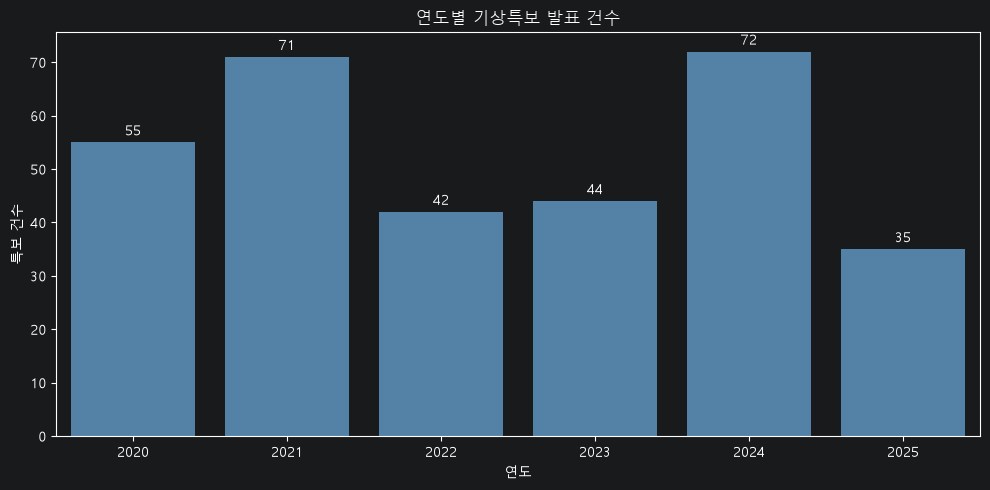

In [18]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=yearly,
    x='연도',
    y='특보건수',
    color='steelblue'
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('연도별 기상특보 발표 건수')
plt.xlabel('연도')
plt.ylabel('특보 건수')
plt.tight_layout()
plt.show()

### 3. 연도별, 월별 특보 건수 분석

In [19]:
monthly = (
    eda_df.groupby(['연도', '월'])
    .size()
    .reset_index(name='특보건수')
)

display(monthly.head(12))

,연도,월,특보건수
0,2020,1,5
1,2020,2,4
2,2020,3,6
3,2020,4,5
4,2020,5,4
5,2020,6,2
6,2020,7,5
7,2020,8,6
8,2020,9,10
9,2020,10,2


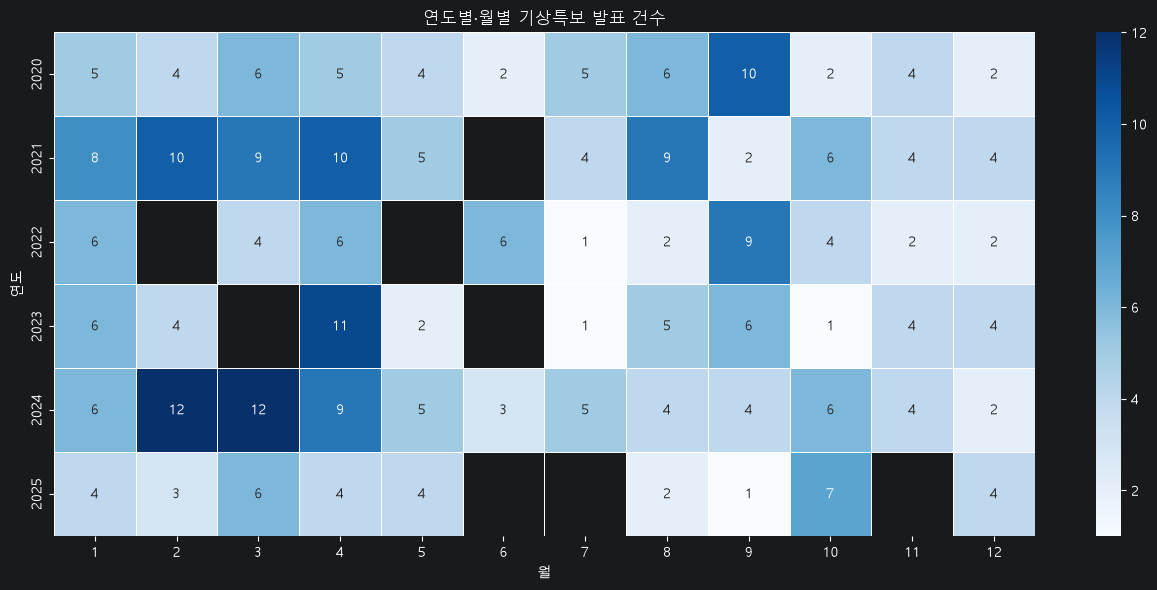

In [20]:
# 히트맵용 데이터 변환
heatmap_data = monthly.pivot(
    index='연도',
    columns='월',
    values='특보건수'
)

# 1~12월 순서 고정
heatmap_data = heatmap_data.reindex(columns=range(1, 13))

plt.figure(figsize=(13, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.0f',
    cmap='Blues',
    linewidths=0.5
)

plt.title('연도별·월별 기상특보 발표 건수')
plt.xlabel('월')
plt.ylabel('연도')
plt.tight_layout()
plt.show()

### 4. 특보종류별 발표 건수

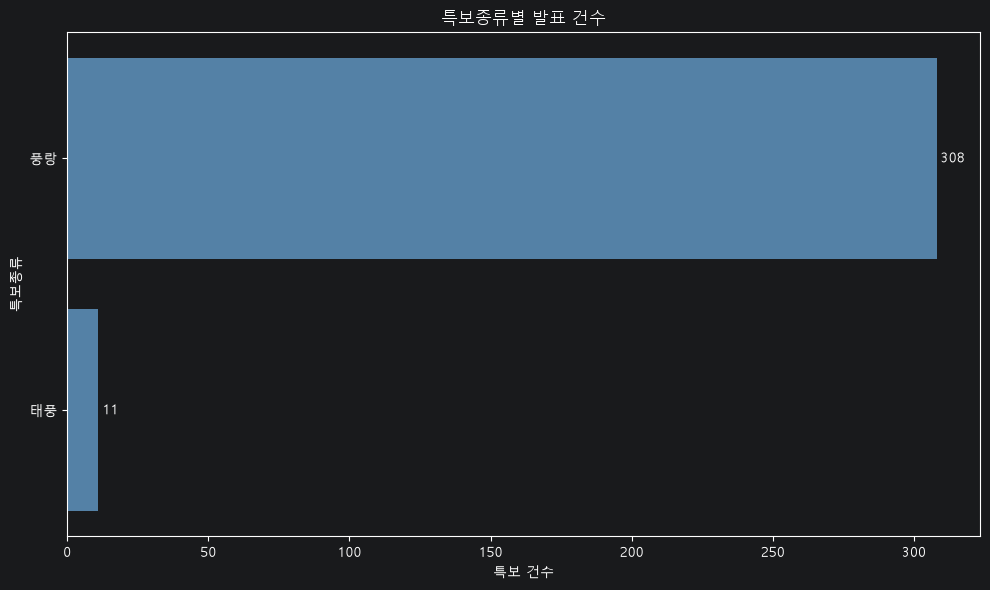

In [21]:
warning_count = (
    eda_df['특보종류']
    .value_counts()
    .reset_index(name='특보건수')
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=warning_count,
    x='특보건수',
    y='특보종류',
    color='steelblue'
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('특보종류별 발표 건수')
plt.xlabel('특보 건수')
plt.ylabel('특보종류')
plt.tight_layout()
plt.show()

### 5. 연도별 특보종류 분포

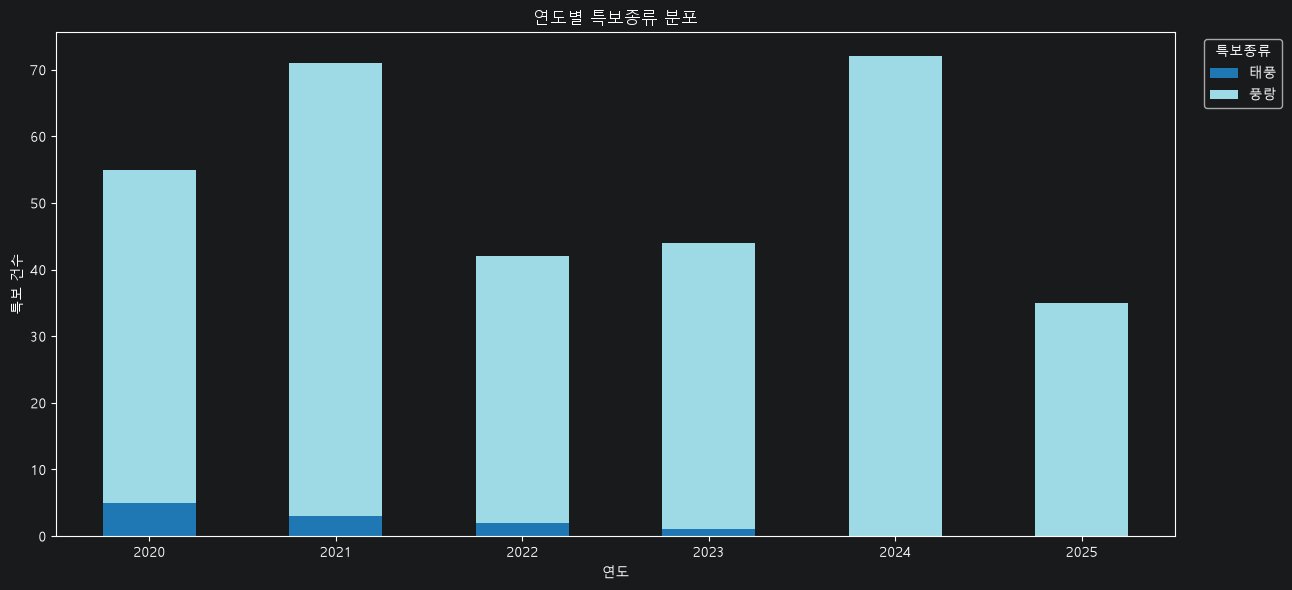

In [22]:
year_warning = (
    eda_df.groupby(['연도', '특보종류'])
    .size()
    .unstack(fill_value=0)
)

ax = year_warning.plot(
    kind='bar',
    stacked=True,
    figsize=(13, 6),
    colormap='tab20'
)

plt.title('연도별 특보종류 분포')
plt.xlabel('연도')
plt.ylabel('특보 건수')
plt.xticks(rotation=0)
plt.legend(title='특보종류', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

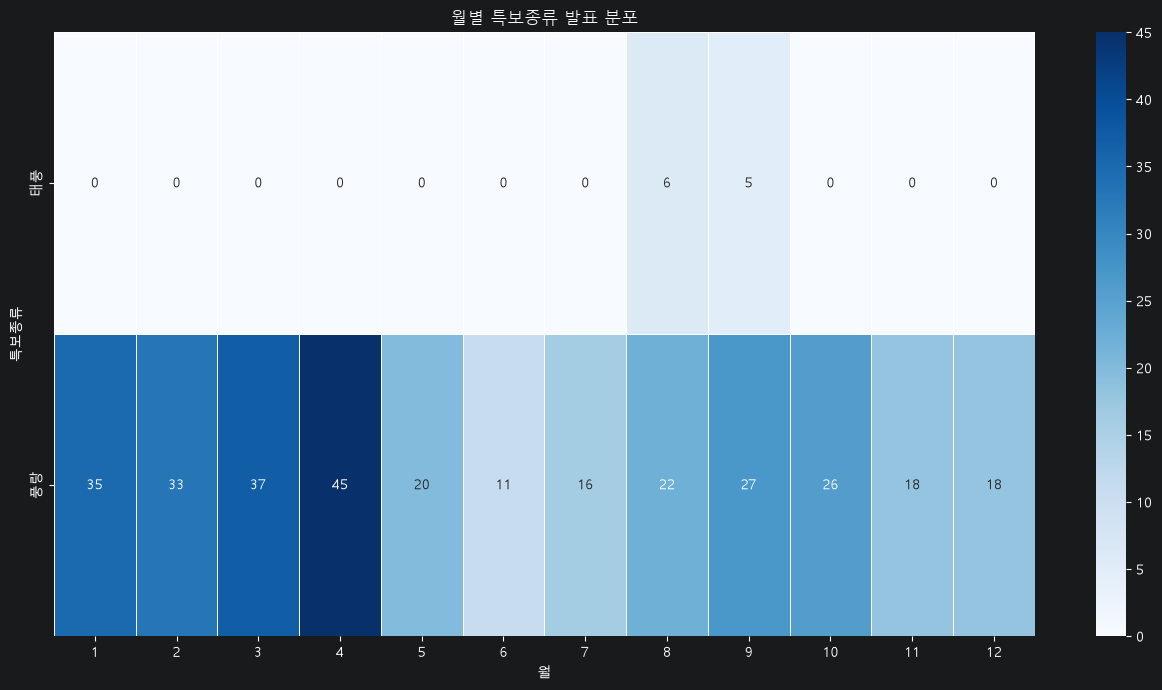

In [23]:
month_warning = (
    eda_df.groupby(['특보종류', '월'])
    .size()
    .unstack(fill_value=0)
)

month_warning = month_warning.reindex(
    columns=range(1, 13),
    fill_value=0
)

plt.figure(figsize=(13, 7))

sns.heatmap(
    month_warning,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=0.5
)

plt.title('월별 특보종류 발표 분포')
plt.xlabel('월')
plt.ylabel('특보종류')
plt.tight_layout()
plt.show()

### 6. 강풍, 풍랑, 태풍의 연도별 월간 추이

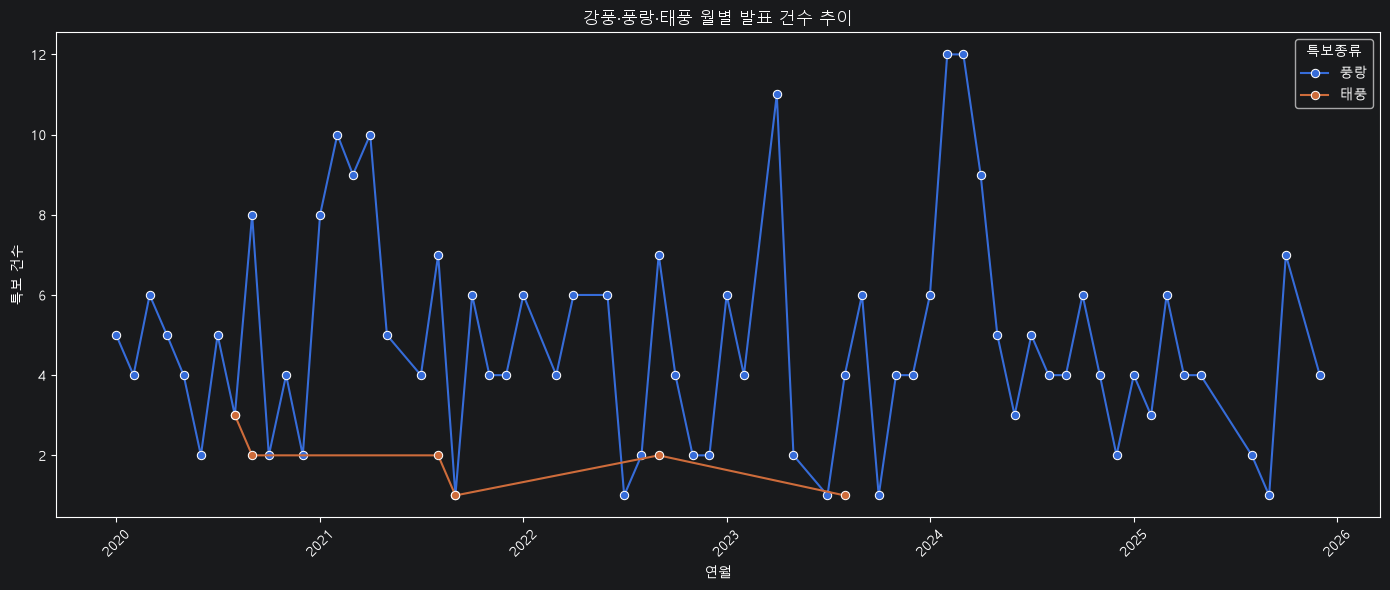

In [24]:
# 주요 특보만 추출
target_df = eda_df[
    eda_df['특보종류'].isin(['강풍', '풍랑', '태풍'])
].copy()

# 연도-월 생성
target_df['연월'] = (
    target_df['발효시각'].dt.to_period('M').dt.to_timestamp()
)

trend = (
    target_df.groupby(['연월', '특보종류'])
    .size()
    .reset_index(name='특보건수')
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=trend,
    x='연월',
    y='특보건수',
    hue='특보종류',
    marker='o'
)

plt.title('강풍·풍랑·태풍 월별 발표 건수 추이')
plt.xlabel('연월')
plt.ylabel('특보 건수')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

부산항 운영에 영향을 미쳤을 가능성이 높은 주요 기상특보 사례 선정
(주요 기상특보 사건 목록: 특보종류,특보수준, 시작시각, 종료시각, 지속시간)

- 특보수준이 2(주의보) 이상인 기록만 목록 추출
|컬럼명|설명|
|---|---|
|특보종류|태풍, 풍랑, 강풍 등|
|특보수준| 2:주의보, 3:경보, 4:중대경보|
|시작시각|특보가 발효되기 시작한 시각|
|종료시각| 해당 특보가 해제된 시각|
|지속시간| 종료시각 - 시작시각|



In [25]:
# 1. 특보수준을 숫자로

df['특보수준'] = pd.to_numeric(
    df['특보수준'],
    errors='coerce'
)

# 특보수준 분포 확인
display(
    df.groupby(['특보수준', '조치'])
    .size()
    .unstack(fill_value=0)
)

조치,발표,변경,변경해제,연장,해제
특보수준,,,,,
1,157,0,0,0,8
2,162,19,6,7,162
3,0,17,7,0,0


#2. 사건별 시작,종료시각추출

- 동일한 예보구역코드 + 특보종류를 하나의 추적 단위로 사용
- 특보수준 2 이상인 최초 기록을 시작으로 판단
- 발표·대치·연장·변경은 진행 중인 사건의 연속 기록으로 처리
- 해제·대치해제(자동)·변경해제는 종료 기록으로 처리
- 특보수준은 해당 사건에서 관측된 최댓값으로 기록

In [26]:
# 날짜형 변환
df['발효시각'] = pd.to_datetime(df['발효시각'])

# 시간순 정렬
temp = df.sort_values(
    ['예보구역코드', '특보종류', '발효시각', '발표시각']
).copy()

end_cmds = ['해제', '대치해제(자동)', '변경해제']

events = []

for (region, warning), group in temp.groupby(
    ['예보구역코드', '특보종류']
):
    start = None
    max_level = None

    for _, row in group.iterrows():
        time = row['발효시각']
        level = row['특보수준']
        cmd = row['조치']

        if pd.isna(time):
            continue

        # 특보 종료
        if cmd in end_cmds:
            if start is not None and time >= start:
                events.append({
                    '예보구역코드': region,
                    '특보종류': warning,
                    '특보수준': max_level,
                    '시작시각': start,
                    '종료시각': time
                })

            start = None
            max_level = None
            continue

        # 새로운 특보 시작
        if start is None:
            if pd.notna(level) and level >= 2:
                start = time
                max_level = level

        # 진행 중인 특보의 수준 갱신
        elif pd.notna(level):
            max_level = max(max_level, level)

# 사건 목록 생성
event_df = pd.DataFrame(
    events,
    columns=[
        '예보구역코드', '특보종류', '특보수준',
        '시작시각', '종료시각'
    ]
)

# 지속시간 계산 (시간 단위)
event_df['지속시간'] = (
    event_df['종료시각'] - event_df['시작시각']
).dt.total_seconds() / 3600

# 지속시간이 긴 순서대로 정렬
event_df = event_df.sort_values(
    '지속시간', ascending=False
).reset_index(drop=True)



In [27]:

# 지속시간이 긴 순서대로 전체 정렬
event_df = (
    event_df
    .sort_values(by='지속시간', ascending=False)
    .reset_index(drop=True)
)

# 순위 추가
event_df.insert(0, '순위', range(1, len(event_df) + 1))

# 원하는 컬럼 순서로 정리
event_df = event_df[
    ['순위', '특보종류', '특보수준',
     '시작시각', '종료시각', '지속시간', '예보구역코드']
]

# 전체 데이터 확인
display(event_df)

,순위,특보종류,특보수준,시작시각,종료시각,지속시간,예보구역코드
0,1,풍랑,2,2024-02-20 11:00:00,2024-02-24 12:00:00,97.0,S1311100
1,2,풍랑,2,2023-05-05 09:00:00,2023-05-08 18:00:00,81.0,S1311100
2,3,풍랑,3,2025-03-02 19:00:00,2025-03-06 04:00:00,81.0,S1311100
3,4,풍랑,2,2022-09-02 20:00:00,2022-09-05 19:00:00,71.0,S1311100
4,5,풍랑,3,2020-10-08 02:00:00,2020-10-11 00:00:00,70.0,S1311100
...,...,...,...,...,...,...,...
170,171,풍랑,2,2024-01-10 14:00:00,2024-01-10 20:00:00,6.0,S1311100
171,172,풍랑,3,2022-09-06 12:00:00,2022-09-06 17:00:00,5.0,S1311100
172,173,풍랑,2,2022-09-10 15:00:00,2022-09-10 20:00:00,5.0,S1311100
173,174,풍랑,2,2021-04-30 05:00:00,2021-04-30 10:00:00,5.0,S1311100


In [28]:
from pathlib import Path

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

event_df.to_csv(
    OUTPUT_DIR / '주요기상특보_지속시간순.csv',
    index=False,
    encoding='utf-8-sig'
)

print(f'전체 {len(event_df):,}건 저장 완료!')

전체 175건 저장 완료!


분석기간: 2021년~2025년


,표본수,평균,중앙값,최소,최대,평균−중앙값
특보종류,,,,,,
풍랑,140,25.43,20.0,4.0,97.0,5.43
태풍,5,17.00,17.0,10.0,25.0,0.00


C:\Users\hjy42\AppData\Local\Temp\ipykernel_27800\1991347148.py:271: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\work\Port_Cast_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


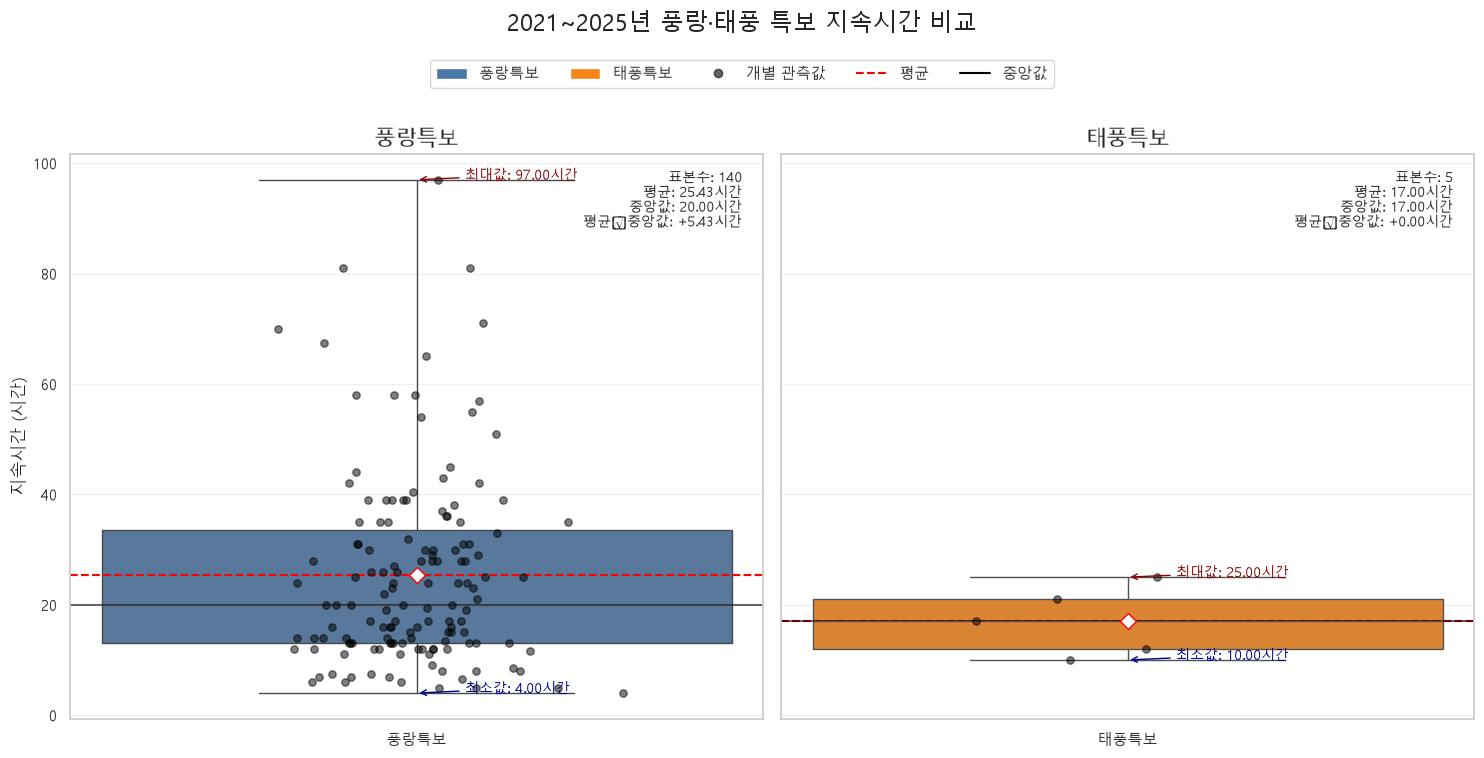

,특보종류,시작시각,종료시각,지속시간
0,태풍,2021-08-23 19:00:00,2021-08-24 05:00:00,10.0
1,태풍,2021-09-17 06:00:00,2021-09-17 18:00:00,12.0
2,태풍,2022-09-05 19:00:00,2022-09-06 12:00:00,17.0
3,태풍,2022-09-18 18:00:00,2022-09-19 15:00:00,21.0
4,태풍,2023-08-09 15:30:00,2023-08-10 16:30:00,25.0
...,...,...,...,...
140,풍랑,2024-09-21 03:00:00,2024-09-24 01:00:00,70.0
141,풍랑,2022-09-02 20:00:00,2022-09-05 19:00:00,71.0
142,풍랑,2023-05-05 09:00:00,2023-05-08 18:00:00,81.0
143,풍랑,2025-03-02 19:00:00,2025-03-06 04:00:00,81.0


In [29]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib import font_manager as fm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns

set_korean_font()
plt.rcParams['axes.unicode_minus'] = False


# -----------------------------
# 1. CSV 불러오기
# -----------------------------
FILE = OUTPUT_DIR / '주요기상특보_지속시간순.csv'

df = pd.read_csv(FILE, encoding="utf-8-sig")

df["시작시각"] = pd.to_datetime(df["시작시각"])
df["종료시각"] = pd.to_datetime(df["종료시각"])
df["지속시간"] = pd.to_numeric(df["지속시간"])

# 2021년~2025년만 사용
df = df[
    (df["시작시각"] >= "2021-01-01")
    & (df["시작시각"] < "2026-01-01")
].copy()

# 풍랑·태풍만 선택
target_types = ["풍랑", "태풍"]

plot_df = df[
    df["특보종류"].isin(target_types)
].copy()

plot_df["지속시간_시간"] = plot_df["지속시간"]


# -----------------------------
# 2. 통계 계산
# -----------------------------
summary = (
    plot_df
    .groupby("특보종류")["지속시간_시간"]
    .agg(
        표본수="count",
        평균="mean",
        중앙값="median",
        최소="min",
        최대="max",
    )
    .reindex(target_types)
)

summary["평균−중앙값"] = (
    summary["평균"] - summary["중앙값"]
)

print("분석기간: 2021년~2025년")
display(summary.round(2))


# -----------------------------
# 3. 한글 폰트 설정
# -----------------------------
available_fonts = {
    font.name for font in fm.fontManager.ttflist
}

font_candidates = [
    "AppleGothic",
    "Malgun Gothic",
    "NanumGothic",
    "Noto Sans CJK KR",
]

selected_font = next(
    (font for font in font_candidates if font in available_fonts),
    "DejaVu Sans",
)

plt.rcParams["font.family"] = selected_font
plt.rcParams["axes.unicode_minus"] = False

sns.set_theme(style="whitegrid")
set_korean_font()  # set_theme이 글꼴을 Arial로 되돌리므로 다시 지정


# -----------------------------
# 4. 박스플롯 그리기
# -----------------------------
colors = {
    "풍랑": "#4C78A8",
    "태풍": "#F58518",
}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 7),
    sharey=True
)

rng = np.random.default_rng(42)

for ax, warning_type in zip(axes, target_types):

    values = plot_df.loc[
        plot_df["특보종류"] == warning_type,
        "지속시간_시간"
    ].to_numpy()

    stats = summary.loc[warning_type]

    # 박스플롯
    sns.boxplot(
        y=values,
        color=colors[warning_type],
        width=0.4,
        whis=(0, 100),
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "white",
            "markeredgecolor": "red",
            "markersize": 8,
        },
        ax=ax,
    )

    # 개별 관측값 표시
    jitter_x = rng.normal(0, 0.045, size=len(values))

    ax.scatter(
        jitter_x,
        values,
        color="black",
        alpha=0.5,
        s=28,
        zorder=3,
    )

    # 평균선과 중앙값선
    ax.axhline(
        stats["평균"],
        color="red",
        linestyle="--",
        linewidth=1.5,
    )

    ax.axhline(
        stats["중앙값"],
        color="black",
        linestyle="-",
        linewidth=1.2,
        alpha=0.7,
    )

    # 최소·최대·평균·중앙값 숫자 표시
    ax.annotate(
        f"최대값: {stats['최대']:.2f}시간",
        xy=(0, stats["최대"]),
        xytext=(35, 0),
        textcoords="offset points",
        color="darkred",
        fontsize=10,
        arrowprops=dict(arrowstyle="->", color="darkred"),
    )

    ax.annotate(
        f"최소값: {stats['최소']:.2f}시간",
        xy=(0, stats["최소"]),
        xytext=(35, 0),
        textcoords="offset points",
        color="darkblue",
        fontsize=10,
        arrowprops=dict(arrowstyle="->", color="darkblue"),
    )

    # 통계 요약 박스
    text_box = (
        f"표본수: {int(stats['표본수'])}\n"
        f"평균: {stats['평균']:.2f}시간\n"
        f"중앙값: {stats['중앙값']:.2f}시간\n"
        f"평균−중앙값: {stats['평균−중앙값']:+.2f}시간"
    )

    ax.text(
        0.97,
        0.97,
        text_box,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            alpha=0.9,
        ),
    )

    ax.set_title(f"{warning_type}특보", fontsize=15)
    ax.set_xlabel("")
    ax.set_ylabel("지속시간 (시간)")
    ax.set_xticks([0])
    ax.set_xticklabels([f"{warning_type}특보"])
    ax.grid(axis="y", alpha=0.3)


# -----------------------------
# 5. 범례
# -----------------------------
legend_handles = [
    Patch(
        facecolor=colors["풍랑"],
        label="풍랑특보"
    ),
    Patch(
        facecolor=colors["태풍"],
        label="태풍특보"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="black",
        linestyle="None",
        alpha=0.6,
        label="개별 관측값"
    ),
    Line2D(
        [0],
        [0],
        color="red",
        linestyle="--",
        label="평균"
    ),
    Line2D(
        [0],
        [0],
        color="black",
        linestyle="-",
        label="중앙값"
    ),
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=5,
    bbox_to_anchor=(0.5, 1.02),
    frameon=True,
)

fig.suptitle(
    "2021~2025년 풍랑·태풍 특보 지속시간 비교",
    fontsize=17,
    y=1.08,
)

plt.tight_layout()
plt.show()


# -----------------------------
# 6. 실제 원자료 값 확인
# -----------------------------
display(
    plot_df[
        [
            "특보종류",
            "시작시각",
            "종료시각",
            "지속시간",
        ]
    ]
    .sort_values(["특보종류", "지속시간"])
    .reset_index(drop=True)
)

In [30]:
from pathlib import Path
import pandas as pd

FILE = OUTPUT_DIR / '주요기상특보_지속시간순.csv'

# CSV 불러오기
df = pd.read_csv(FILE, encoding="utf-8-sig")

print("컬럼:", df.columns.tolist())
print("전체 데이터:", df.shape)

# 날짜와 지속시간 변환
df["시작시각"] = pd.to_datetime(df["시작시각"])
df["종료시각"] = pd.to_datetime(df["종료시각"])
df["지속시간"] = pd.to_numeric(df["지속시간"])

# 2021년~2025년 필터
df = df[
    (df["시작시각"] >= "2021-01-01")
    & (df["시작시각"] < "2026-01-01")
].copy()

# 지속시간 단위 검증
df["계산된_지속시간_시간"] = (
    df["종료시각"] - df["시작시각"]
).dt.total_seconds() / 3600

df["시간차이"] = (
    df["지속시간"] - df["계산된_지속시간_시간"]
)

if (df["시간차이"].abs() < 1e-9).all():
    print("지속시간 검증 완료: 모든 값이 시간 단위로 일치합니다.")
else:
    print("지속시간 불일치 행:")
    display(df[df["시간차이"].abs() >= 1e-9])

# 박스플롯에 사용할 컬럼
df["지속시간_시간"] = df["지속시간"]

print("필터링 후 데이터 수:", len(df))
print(df["특보종류"].value_counts())

컬럼: ['순위', '특보종류', '특보수준', '시작시각', '종료시각', '지속시간', '예보구역코드']
전체 데이터: (175, 7)
지속시간 검증 완료: 모든 값이 시간 단위로 일치합니다.
필터링 후 데이터 수: 145
특보종류
풍랑    140
태풍      5
Name: count, dtype: int64


In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager as fm

sns.set_theme(style="whitegrid")
set_korean_font()  # set_theme이 글꼴을 Arial로 되돌리므로 다시 지정

print("사용 폰트:", set_korean_font())

사용 폰트: Malgun Gothic


In [32]:
from pathlib import Path
from matplotlib import font_manager as fm
import matplotlib.pyplot as plt
import seaborn as sns

# 먼저 seaborn 스타일 적용
sns.set_theme(style="whitegrid")
set_korean_font()  # set_theme이 글꼴을 Arial로 되돌리므로 다시 지정

print("사용 폰트:", set_korean_font())

사용 폰트: Malgun Gothic


In [33]:
plt.close("all")

In [34]:
set_korean_font()  # Arial은 한글이 없어 깨짐

'Malgun Gothic'

사용 폰트: Malgun Gothic
2021~2025년 통계


,표본수,평균,중앙값,최소,최대,평균−중앙값
특보종류,,,,,,
풍랑,140,25.43,20.0,4.0,97.0,5.43
태풍,5,17.00,17.0,10.0,25.0,0.00


C:\Users\hjy42\AppData\Local\Temp\ipykernel_27800\353105326.py:245: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\work\Port_Cast_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


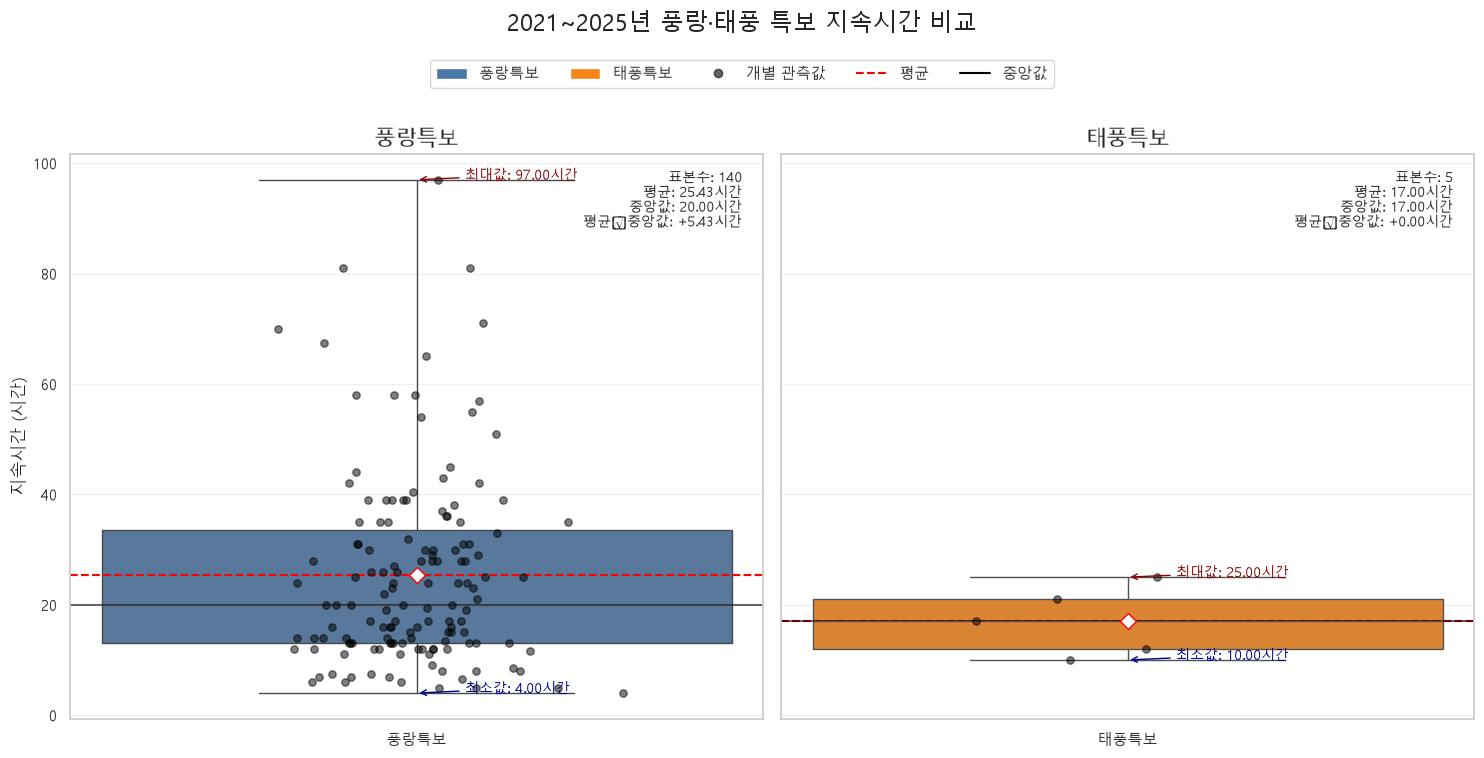

,특보종류,시작시각,종료시각,지속시간
0,태풍,2021-08-23 19:00:00,2021-08-24 05:00:00,10.0
1,태풍,2021-09-17 06:00:00,2021-09-17 18:00:00,12.0
2,태풍,2022-09-05 19:00:00,2022-09-06 12:00:00,17.0
3,태풍,2022-09-18 18:00:00,2022-09-19 15:00:00,21.0
4,태풍,2023-08-09 15:30:00,2023-08-10 16:30:00,25.0
...,...,...,...,...
140,풍랑,2024-09-21 03:00:00,2024-09-24 01:00:00,70.0
141,풍랑,2022-09-02 20:00:00,2022-09-05 19:00:00,71.0
142,풍랑,2023-05-05 09:00:00,2023-05-08 18:00:00,81.0
143,풍랑,2025-03-02 19:00:00,2025-03-06 04:00:00,81.0


In [35]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib import font_manager as fm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


# -----------------------------
# 1. 한글 폰트 설정
# -----------------------------
sns.set_theme(style="whitegrid")
set_korean_font()  # set_theme이 글꼴을 Arial로 되돌리므로 다시 지정

print("사용 폰트:", set_korean_font())


# -----------------------------
# 2. CSV 불러오기
# -----------------------------
FILE = OUTPUT_DIR / '주요기상특보_지속시간순.csv'

df = pd.read_csv(FILE, encoding="utf-8-sig")

df["시작시각"] = pd.to_datetime(df["시작시각"])
df["종료시각"] = pd.to_datetime(df["종료시각"])
df["지속시간"] = pd.to_numeric(df["지속시간"])

# 2021~2025년만 선택
df = df[
    (df["시작시각"] >= "2021-01-01")
    & (df["시작시각"] < "2026-01-01")
].copy()

target_types = ["풍랑", "태풍"]

plot_df = df[
    df["특보종류"].isin(target_types)
].copy()

plot_df["지속시간_시간"] = plot_df["지속시간"]


# -----------------------------
# 3. 통계 계산
# -----------------------------
summary = (
    plot_df
    .groupby("특보종류")["지속시간_시간"]
    .agg(
        표본수="count",
        평균="mean",
        중앙값="median",
        최소="min",
        최대="max",
    )
    .reindex(target_types)
)

summary["평균−중앙값"] = (
    summary["평균"] - summary["중앙값"]
)

print("2021~2025년 통계")
display(summary.round(2))


# -----------------------------
# 4. 박스플롯 작성
# -----------------------------
colors = {
    "풍랑": "#4C78A8",
    "태풍": "#F58518",
}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 7),
    sharey=True
)

rng = np.random.default_rng(42)

for ax, warning_type in zip(axes, target_types):

    values = plot_df.loc[
        plot_df["특보종류"] == warning_type,
        "지속시간_시간"
    ].to_numpy()

    stats = summary.loc[warning_type]

    # 박스플롯
    sns.boxplot(
        y=values,
        color=colors[warning_type],
        width=0.4,
        whis=(0, 100),
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "white",
            "markeredgecolor": "red",
            "markersize": 8,
        },
        ax=ax,
    )

    # 개별 데이터 점
    jitter_x = rng.normal(0, 0.045, size=len(values))

    ax.scatter(
        jitter_x,
        values,
        color="black",
        alpha=0.5,
        s=28,
        zorder=3,
    )

    # 평균선
    ax.axhline(
        stats["평균"],
        color="red",
        linestyle="--",
        linewidth=1.5,
    )

    # 중앙값선
    ax.axhline(
        stats["중앙값"],
        color="black",
        linestyle="-",
        linewidth=1.2,
        alpha=0.7,
    )

    # 최소·최대값 표시
    ax.annotate(
        f"최대값: {stats['최대']:.2f}시간",
        xy=(0, stats["최대"]),
        xytext=(35, 0),
        textcoords="offset points",
        color="darkred",
        fontsize=10,
        arrowprops=dict(arrowstyle="->", color="darkred"),
    )

    ax.annotate(
        f"최소값: {stats['최소']:.2f}시간",
        xy=(0, stats["최소"]),
        xytext=(35, 0),
        textcoords="offset points",
        color="darkblue",
        fontsize=10,
        arrowprops=dict(arrowstyle="->", color="darkblue"),
    )

    # 평균·중앙값 숫자 표시
    info = (
        f"표본수: {int(stats['표본수'])}\n"
        f"평균: {stats['평균']:.2f}시간\n"
        f"중앙값: {stats['중앙값']:.2f}시간\n"
        f"평균−중앙값: {stats['평균−중앙값']:+.2f}시간"
    )

    ax.text(
        0.97,
        0.97,
        info,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            alpha=0.9,
        ),
    )

    ax.set_title(f"{warning_type}특보", fontsize=15)
    ax.set_xlabel("")
    ax.set_ylabel("지속시간 (시간)")
    ax.set_xticks([0])
    ax.set_xticklabels([f"{warning_type}특보"])
    ax.grid(axis="y", alpha=0.3)


# -----------------------------
# 5. 범례
# -----------------------------
legend_handles = [
    Patch(
        facecolor=colors["풍랑"],
        label="풍랑특보"
    ),
    Patch(
        facecolor=colors["태풍"],
        label="태풍특보"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="black",
        linestyle="None",
        alpha=0.6,
        label="개별 관측값"
    ),
    Line2D(
        [0],
        [0],
        color="red",
        linestyle="--",
        label="평균"
    ),
    Line2D(
        [0],
        [0],
        color="black",
        linestyle="-",
        label="중앙값"
    ),
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=5,
    bbox_to_anchor=(0.5, 1.02),
)

fig.suptitle(
    "2021~2025년 풍랑·태풍 특보 지속시간 비교",
    fontsize=17,
    y=1.08,
)

plt.tight_layout()
plt.show()


# -----------------------------
# 6. 실제 원자료 확인
# -----------------------------
display(
    plot_df[
        ["특보종류", "시작시각", "종료시각", "지속시간"]
    ]
    .sort_values(["특보종류", "지속시간"])
    .reset_index(drop=True)
)